<a href="https://colab.research.google.com/github/karimovamaria279/bank_reviews_clustering/blob/main/bank_reviews_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings
warnings.filterwarnings('ignore')

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

plt.style.use('ggplot')
%matplotlib inline

In [22]:
from google.colab import drive
drive.mount('/content/drive')

# Укажи путь к файлу на Google Диске
df = pd.read_csv('/content/drive/MyDrive/final_review_dataset_extended.csv')

# Убираем лишний столбец с индексом
df = df.drop(columns=['Unnamed: 0'], errors='ignore')

# Удаляем строки без текста отзыва или оценки
df = df.dropna(subset=['review', 'rating_value'])

print(f"Размер данных: {df.shape}")
print(f"Столбцы: {df.columns.tolist()}")
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Размер данных: (12392, 15)
Столбцы: ['bank', 'type', 'user_name', 'review_title', 'review', 'review_dttm', 'review_views', 'review_comments', 'rating_value', 'Вежливые сотрудники', 'Доступность и поддержка', 'Прозрачные условия', 'Удобство приложения, сайта', 'review_len', 'review_len_in_tokens']


,bank,type,user_name,review_title,review,review_dttm,review_views,review_comments,rating_value,Вежливые сотрудники,Доступность и поддержка,Прозрачные условия,"Удобство приложения, сайта",review_len,review_len_in_tokens
0,Россельхозбанк,Person,user-430412136020,Открытие счета ИП,Добрый день! Я являюсь ИП и стоял перед выборо...,2023-05-02,773,0,5,3.0,3.0,3.0,3.0,171.0,363.0
1,Россельхозбанк,Person,user-60268947545,Спасибо за помощь,Здравствуйте! Достаточно давно являюсь клиенто...,2023-04-02,560,0,5,3.0,3.0,3.0,3.0,66.0,149.0
2,Банк ДОМ.РФ,Person,user-294212759595,Отличный сервис,"Здравствуйте,являюсь клиентом банка с ноября 2...",2023-03-02,737,1,5,3.0,3.0,3.0,3.0,70.0,164.0
3,Альфа-Банк,Person,user-841712733484,Блокировка денежных средств,14 января 2023 года была попытка перевода дене...,2023-01-02,627,3,1,NaN,NaN,NaN,NaN,170.0,337.0
4,Банк «Открытие»,Person,NaN,Хамство сотрудников Открытия,"У меня сложилось устойчивое впечатление, что в...",2023-01-02,517,31,1,1.0,1.0,1.0,1.0,106.0,210.0


In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12392 entries, 0 to 12391
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   bank                        12392 non-null  object 
 1   type                        12392 non-null  object 
 2   user_name                   12361 non-null  object 
 3   review_title                12388 non-null  object 
 4   review                      12392 non-null  object 
 5   review_dttm                 12392 non-null  object 
 6   review_views                12392 non-null  int64  
 7   review_comments             12392 non-null  int64  
 8   rating_value                12392 non-null  int64  
 9   Вежливые сотрудники         11377 non-null  float64
 10  Доступность и поддержка     11377 non-null  float64
 11  Прозрачные условия          11377 non-null  float64
 12  Удобство приложения, сайта  11377 non-null  float64
 13  review_len                  123

In [24]:
df.describe()

,review_views,review_comments,rating_value,Вежливые сотрудники,Доступность и поддержка,Прозрачные условия,"Удобство приложения, сайта",review_len,review_len_in_tokens
count,12392.000000,12392.000000,12392.000000,11377.000000,11377.000000,11377.000000,11377.000000,12392.000000,12392.000000
mean,1548.677130,2.070771,2.845465,2.319856,2.319856,2.319856,2.319856,149.578518,308.629842
std,2107.490696,2.939095,1.875967,0.837282,0.837282,0.837282,0.837282,114.800003,230.269231
min,326.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,13.000000,27.000000
25%,1027.000000,0.000000,1.000000,2.000000,2.000000,2.000000,2.000000,68.000000,146.000000
50%,1186.000000,1.000000,2.000000,3.000000,3.000000,3.000000,3.000000,110.000000,230.000000
75%,1487.000000,3.000000,5.000000,3.000000,3.000000,3.000000,3.000000,190.000000,388.000000
max,78811.000000,50.000000,5.000000,3.000000,3.000000,3.000000,3.000000,945.000000,1928.000000


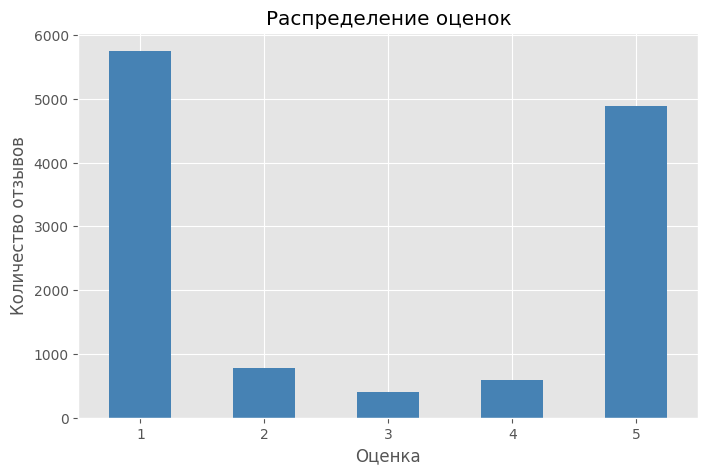

In [25]:
# Распределение оценок
plt.figure(figsize=(8, 5))
df['rating_value'].value_counts().sort_index().plot(kind='bar', color='steelblue')
plt.title('Распределение оценок')
plt.xlabel('Оценка')
plt.ylabel('Количество отзывов')
plt.xticks(rotation=0)
plt.show()

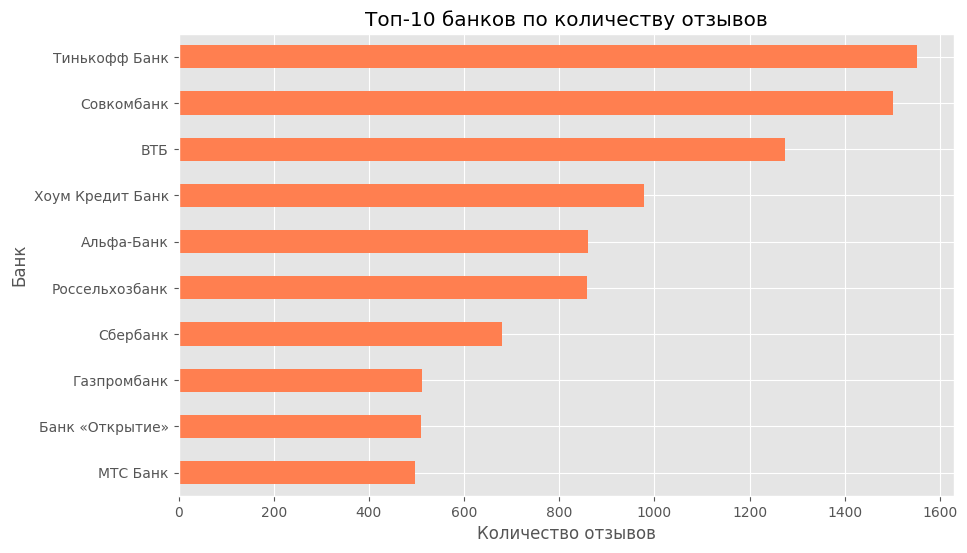

In [20]:
plt.figure(figsize=(10,6))
df['bank'].value_counts().head(10).plot(kind='barh', color='coral')
plt.title('Топ-10 банков по количеству отзывов')
plt.xlabel('Количество отзывов')
plt.ylabel('Банк')
plt.gca().invert_yaxis()
plt.show()

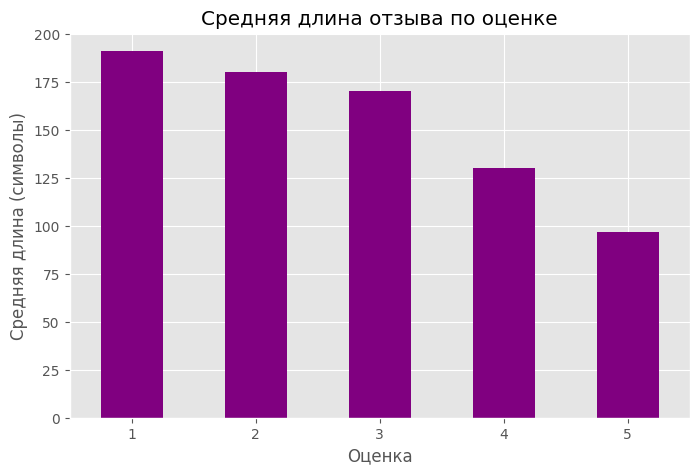

In [27]:
# Средняя длина отзыва по оценке
plt.figure(figsize=(8, 5))
df.groupby('rating_value')['review_len'].mean().plot(kind='bar', color='purple')
plt.title('Средняя длина отзыва по оценке')
plt.xlabel('Оценка')
plt.ylabel('Средняя длина (символы)')
plt.xticks(rotation=0)
plt.show()

In [28]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^а-яёa-z\s]', ' ', text)  # только буквы
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['clean_review'] = df['review'].apply(clean_text)

# Убираем слишком короткие отзывы
df = df[df['clean_review'].str.len() > 10]

print(f"Размер после очистки: {df.shape}")

Размер после очистки: (12392, 16)


In [29]:
vectorizer = TfidfVectorizer(max_features=3000, min_df=5, max_df=0.7)
X = vectorizer.fit_transform(df['clean_review'])
print(f"Матрица TF-IDF: {X.shape}")

Матрица TF-IDF: (12392, 3000)


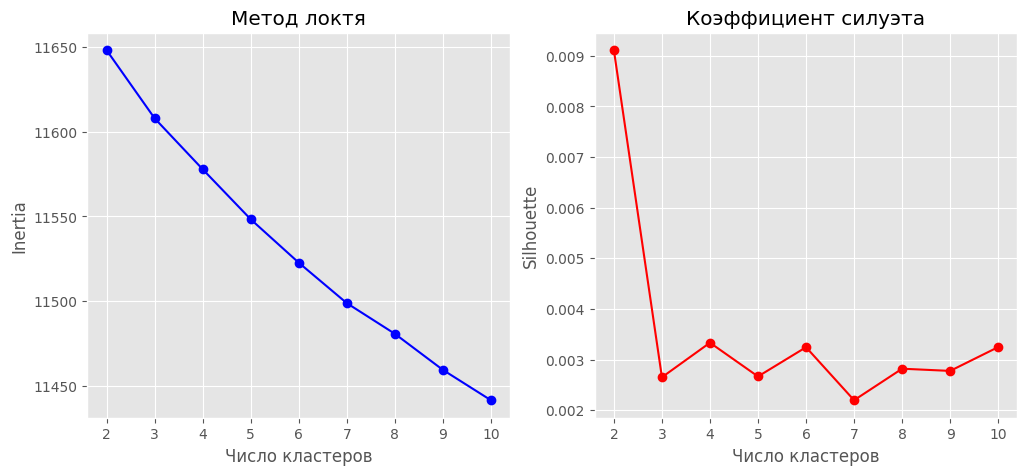

In [30]:
inertia = []
silhouette = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X)
    inertia.append(kmeans.inertia_)
    silhouette.append(silhouette_score(X, labels))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(K_range, inertia, 'bo-')
plt.title('Метод локтя')
plt.xlabel('Число кластеров')
plt.ylabel('Inertia')

plt.subplot(1, 2, 2)
plt.plot(K_range, silhouette, 'ro-')
plt.title('Коэффициент силуэта')
plt.xlabel('Число кластеров')
plt.ylabel('Silhouette')

plt.show()

In [31]:
optimal_k = 5
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X)

print("Распределение по кластерам:")
print(df['cluster'].value_counts().sort_index())

Распределение по кластерам:
cluster
0     932
1    2202
2    4068
3    2148
4    3042
Name: count, dtype: int64


In [32]:
terms = vectorizer.get_feature_names_out()
order_centroids = kmeans.cluster_centers_.argsort()[:, ::-1]

for i in range(optimal_k):
    print(f"\n=== Кластер {i} (топ-10 слов) ===")
    top_words = [terms[ind] for ind in order_centroids[i, :10]]
    print(", ".join(top_words))


=== Кластер 0 (топ-10 слов) ===
акции, по, карту, кэшбэк, условия, мне, покупки, за, банка, рублей

=== Кластер 1 (топ-10 слов) ===
очень, спасибо, за, по, банка, хочу, благодарность, мне, все, выразить

=== Кластер 2 (топ-10 слов) ===
по, банк, деньги, банка, но, за, мне, обращение, до, как

=== Кластер 3 (топ-10 слов) ===
очень, по, все, банка, быстро, всегда, банк, пользуюсь, за, тинькофф

=== Кластер 4 (топ-10 слов) ===
мне, карту, по, то, банка, как, но, это, меня, так


Кластер 0 — Карты и кэшбэк
Кластер 1 — Благодарности
Кластер 2 — Жалобы на обслуживание
Кластер 3 — Позитив о Тинькофф
Кластер 4 — Негатив про карты


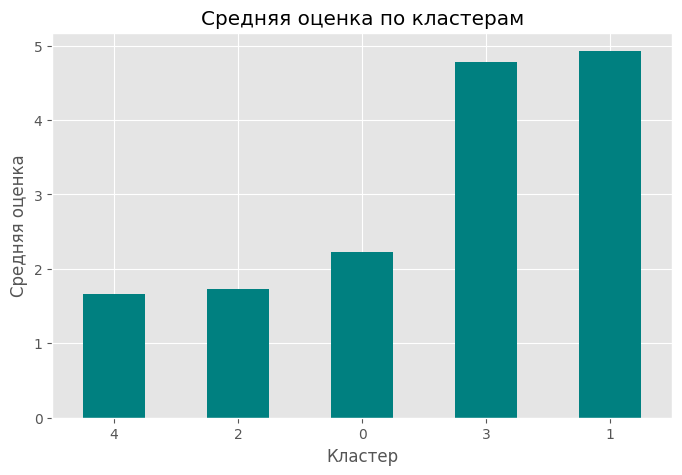

In [37]:
# Интерпретация кластеров
cluster_names = {
    0: "Карты и кэшбэк",
    1: "Благодарности",
    2: "Жалобы на обслуживание",
    3: "Позитив о Тинькофф",
    4: "Негатив про карты"
}

for i in range(optimal_k):
    print(f"Кластер {i} — {cluster_names.get(i, 'Без названия')}")

# Средняя оценка по кластерам
cluster_rating = df.groupby('cluster')['rating_value'].mean().sort_values()

plt.figure(figsize=(8, 5))
cluster_rating.plot(kind='bar', color='teal')
plt.title('Средняя оценка по кластерам')
plt.xlabel('Кластер')
plt.ylabel('Средняя оценка')
plt.xticks(rotation=0)
plt.show()

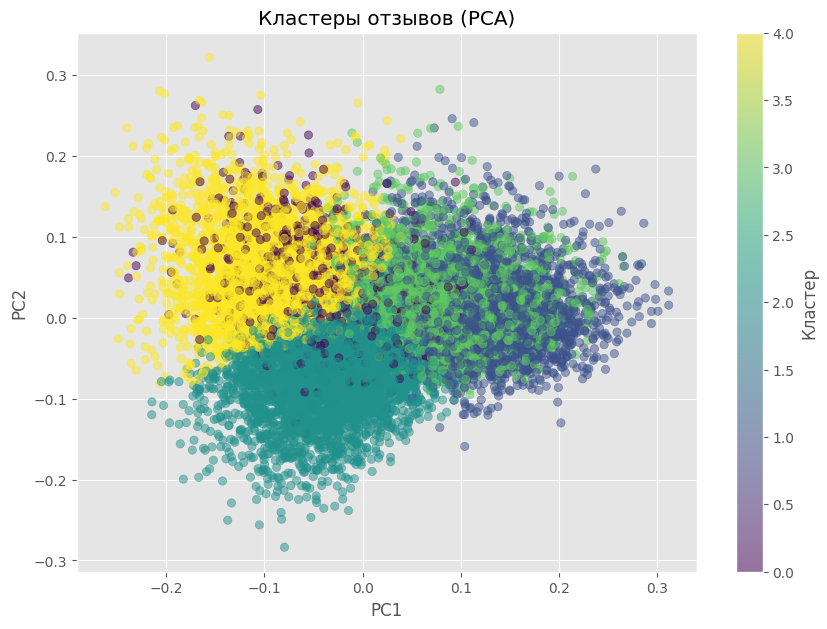

In [33]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X.toarray())

plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df['cluster'], cmap='viridis', alpha=0.5)
plt.title('Кластеры отзывов (PCA)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.colorbar(scatter, label='Кластер')
plt.show()

In [35]:
for i in range(optimal_k):
    print(f"\n=== Кластер {i} — примеры отзывов ===")
    sample = df[df['cluster'] == i]['review'].head(3).tolist()
    for s in sample:
        print(f"- {s[:200]}...")


=== Кластер 0 — примеры отзывов ===
- 26 декабря 2022 года я оформил кредитную карту альфа банка через приложение магазина магнит, но в следующем месяце обещанные 3500 бонусов на карту магнит от банка не получил. Я пытался решить этот воп...
- Так работает Банк Открытие. Получила СМС оферту с предложением открыть кредитную карту за вознаграждение в 1500 бонусных баллов.Там было еще несколько условий, предварительно я еще раз уточнила у сотр...
- 28.11.2023 отправил сестре ссылку на открытие карты Альфа-карта, в декабре она ее оформила, потратила по ней 20 000р, бонус как мне сказали в чат поддержки придет до конца января точно, уже февраль, б...

=== Кластер 1 — примеры отзывов ===
- Добрый день! Я являюсь ИП и стоял перед выбором банка для открытия расчетного счета. Посоветовали обратиться в Россельхозбанк, что я и сделал , и не прогадал. Теперь хочу рассказать о моем впечатлении...
- Здравствуйте! Достаточно давно являюсь клиентом этого банка, 12 января я обратилась в офис Россельхо

In [36]:
print("=== ВЫВОДЫ ===")
print(f"Всего отзывов: {len(df)}")
print(f"Выделено кластеров: {optimal_k}")
print(f"Средняя оценка: {df['rating_value'].mean():.2f}")
print(f"\nТоп-3 банка по отзывам:")
print(df['bank'].value_counts().head(3))
print(f"\nСредняя оценка по кластерам:")
print(cluster_rating)

=== ВЫВОДЫ ===
Всего отзывов: 12392
Выделено кластеров: 5
Средняя оценка: 2.85

Топ-3 банка по отзывам:
bank
Тинькофф Банк    1551
Совкомбанк       1501
ВТБ              1275
Name: count, dtype: int64

Средняя оценка по кластерам:
cluster
4    1.658448
2    1.731072
0    2.221030
3    4.774674
1    4.926431
Name: rating_value, dtype: float64


In [38]:
df.to_csv('bank_reviews_clustered.csv', index=False)
print("Файл сохранён: bank_reviews_clustered.csv")

Файл сохранён: bank_reviews_clustered.csv
